In [70]:
import pandas as pd 
import numpy as np

data = pd.read_csv('Dataset//Churn_Modelling.csv')
data.head()


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [71]:
data.shape

(10000, 14)

In [72]:
df = pd.DataFrame(data)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [73]:
df.duplicated().sum()

np.int64(0)

In [74]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [75]:
df['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [76]:
df['Gender'].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

In [77]:
df = df.drop(['Surname', 'RowNumber', 'CustomerId'], axis=1)

In [78]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [79]:
df = pd.get_dummies(df, columns=['Geography', 'Gender'], drop_first=True)

In [80]:
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False


In [81]:
from sklearn.model_selection import train_test_split

X = df.drop('Exited', axis=1)
y = df['Exited']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [82]:
X_train.shape

(8000, 11)

In [83]:
from sklearn.preprocessing import StandardScaler 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [84]:
X_test_scaled.shape

(2000, 11)

In [85]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential 
from tensorflow.keras.layers import Dense


In [86]:
model = Sequential()
model.add(Dense(3,activation='relu', input_dim = 11))
model.add(Dense(1,activation='sigmoid'))

d:\Notes of CampusX\DL with CampusX\.dlenv\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [87]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 3)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40 (160.00 B)

 Trainable params: 40 (160.00 B)

 Non-trainable params: 0 (0.00 B)

In [88]:
model.compile(loss= 'binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [89]:
history = model.fit(X_train_scaled, y_train, epochs=100, validation_split=0.2)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3073 - loss: 1.0304 - val_accuracy: 0.3806 - val_loss: 0.8319
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5119 - loss: 0.7364 - val_accuracy: 0.6706 - val_loss: 0.6616
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7355 - loss: 0.6251 - val_accuracy: 0.7944 - val_loss: 0.5912
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7983 - loss: 0.5750 - val_accuracy: 0.7994 - val_loss: 0.5554
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8022 - loss: 0.5464 - val_accuracy: 0.8069 - val_loss: 0.5311
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8023 - loss: 0.5248 - val_accuracy: 0.8094 - val_loss: 0.5108
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8062 - loss: 0.5061 - val_accuracy: 0.8181 - val_loss: 0.4929
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8130 - loss: 0.4895 - val_accu

In [90]:
# Layer 1 weights and bias
model.layers[0].get_weights()

[array([[-0.09217739,  0.03386194, -0.07043169],
        [ 0.337413  ,  0.5018449 ,  0.18896127],
        [-0.03475035, -0.03745694,  0.01693773],
        [ 0.4612651 , -0.21926199, -0.16113615],
        [ 1.4751064 , -1.1936679 , -1.1045567 ],
        [-0.05780238,  0.07894327, -0.08898408],
        [-0.20058648, -0.6471094 ,  0.05854344],
        [ 0.01707085, -0.03745083,  0.03213379],
        [-0.08481015,  0.31465632,  0.19252257],
        [ 0.06721617, -0.00964363,  0.04427269],
        [-0.19615318, -0.12440412, -0.06330914]], dtype=float32),
 array([-0.7838573 ,  0.16327973, -0.01277099], dtype=float32)]

In [91]:
# Layer 2 weights and bias
model.layers[1].get_weights()

[array([[1.7681735],
        [1.0326254],
        [1.004569 ]], dtype=float32),
 array([-3.4758842], dtype=float32)]

In [92]:
y_log = model.predict(X_test_scaled)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step  


In [93]:
y_pred = np.where(y_log>0.5,1,0)

In [94]:
import sklearn
print(sklearn.__version__)

1.7.2


In [95]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)
# 0.822 --> with 10 Epochs 
# 0.8635 --> with 1000 Epochs

0.85

In [96]:
import matplotlib.pyplot as plt

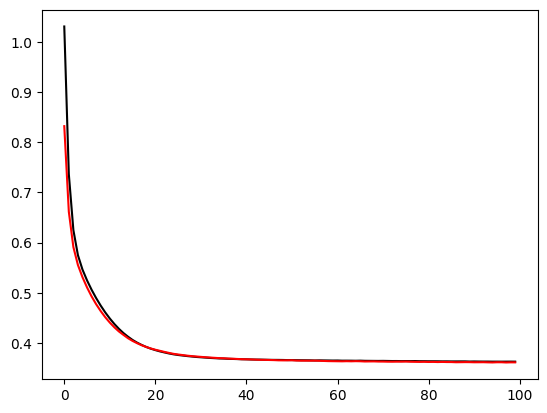

In [97]:
plt.plot(history.history['loss'], label='train_accuracy', color='black')
plt.plot(history.history['val_loss'], label='val_accuracy',color='red')
 

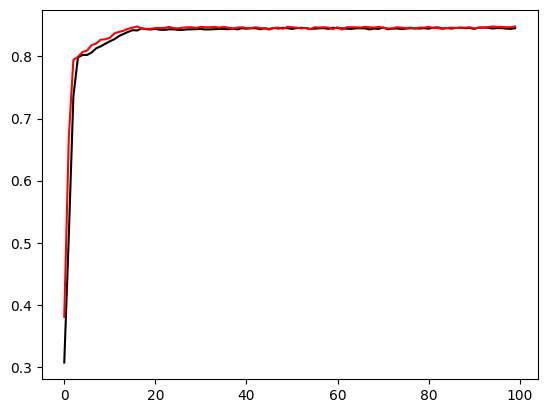

In [98]:
plt.plot(history.history['accuracy'], label='train_accuracy', color='black')
plt.plot(history.history['val_accuracy'], label='val_accuracy',color='red')